# Discretized Indices of Convexity

## Useful dependencies

In [31]:
import numpy as np
import numdifftools as nd
import scipy.linalg as la 
import matplotlib.pyplot as plt

## Useful Variables

In [32]:
# Set parameters
f = lambda x: np.sin(x[0] * x[1])
display_rad = 2
display_shift = 0
display_spacing = 0.25 # if computations are too slow, make the spacing bigger

## Plot the function to be analyzed

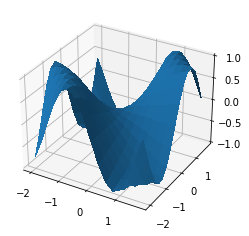

In [33]:
# Plot the function itself
fig = plt.figure()
ax = fig.gca(projection='3d')

# Make data.
X = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Y = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(X, Y)
Z = f([X, Y])

# Plot the surface.
surf = ax.plot_surface(X, Y, Z, linewidth=0, antialiased=False)
# Customize the z axis.
ax.set_zlim(-1, 1)

plt.show()


## Calculate the Hessian and obtain eigenvalues

In [34]:
lamda_1 = lamda_2 = np.zeros(X.shape)

# iterate through the array and calculate the value at each point for lamda_1 and lamda_2, creating two new arrays
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        H = nd.Hessian(f)([i, j])
        eigvals, eigvecs = la.eig(H)
        eigvals = eigvals.real
        lamda_1[i][j] = eigvals[0]
        lamda_2[i][j] = eigvals[1]

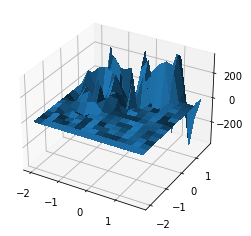

In [40]:
fig1 = plt.figure()
ax1 = fig1.gca(projection='3d')

X = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Y = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(X, Y)
# Plot the surface.
surf1 = ax1.plot_surface(X, Y, lamda_1, linewidth=0, antialiased=False)
# Customize the z axis.
# ax1.set_zlim(-10, 10)
#
plt.show()

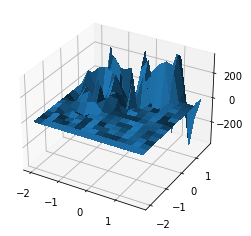

In [42]:
fig2 = plt.figure()
ax2 = fig2.gca(projection='3d')

# Make data.
X = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
Y = np.arange(-display_rad + display_shift, display_rad + display_shift, display_spacing)
X, Y = np.meshgrid(X, Y)
surf2 = ax2.plot_surface(X, Y, lamda_2, linewidth=0, antialiased=False)
plt.show()

In [11]:
# using these new arrays, calculate the max(lamdma, 0) of each one (plot)
zero = np.zeros(X.shape)

lamda_1_plus = np.maximum(zero, lamda_1)
lamda_2_plus = np.maximum(zero, lamda_2)

lamda_1_minus = np.maximum(zero, -1 * lamda_1)
lamda_2_minus = np.maximum(zero, -1 * lamda_2)

## Using these new arrays, plot indices of convexity. 

In [12]:
# The index of lack of convexity (normalized)
loc = (lamda_1_minus + lamda_2_minus) / (np.abs(lamda_1) + np.abs(lamda_2))

In [13]:
# index of convexity (normalized)
conv = (lamda_1_plus + lamda_2_plus) / (np.abs(lamda_1) + np.abs(lamda_2))